<a href="https://colab.research.google.com/github/lior-avital1/3D-Print-Anomaly-Detection/blob/main/notebooks/data_pipeline_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3D Print Failure Detection – Data Pipeline & Baseline Training

מחברת זו בונה את דאטאסט הסיווג מכל המקורות, מנקה אותו, ומאמנת שני מודלי baseline.

**סדר העבודה:**
1. הגדרת סביבה – דרייב, נתיבים, סקריפטים
2. רישום מקורות הדאטה
3. חילוץ ובדיקת מבנה
4. ניקוי כפילויות בדאטה הקיים
5. ייבוא מקורות חדשים (בדיקת כפילויות ← ייבוא)
6. תיקון חלוקת train / val / test
7. סקירת הדאטה
8. הכנת הדאטה לאימון – העתקה מוקטנת לדיסק המקומי (9 מחלקות / 3 קבוצות)
9. אימון
10. הערכה על test

**מבנה הדרייב:**
```
Final_Project/
├── runs/               ← תוצאות אימון (נשמרות בדרייב)
└── DataSet/
    ├── raw/            ← המקורות כפי שהורדו – לא נוגעים
    ├── classification/ ← train/val/test/<class>  (נבנה מ-raw)
    └── sources.csv     ← מקור, קישור ורישיון לכל מאגר
```

> תאים שמסומנים ⚠️ משנים קבצים בדרייב. כולם בטוחים להרצה חוזרת.

## 1. הגדרת סביבה

### 1.1 חיבור לדרייב והתקנות

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q ultralytics roboflow

Mounted at /content/drive


### 1.2 נתיבים
כל הנתיבים מוגדרים כאן פעם אחת. שאר המחברת משתמשת רק במשתנים האלה.

In [3]:
import os, sys, subprocess, shutil, random, csv
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Final_Project")
ROOT    = PROJECT / "DataSet"
RAW     = ROOT / "raw"
CLS     = ROOT / "classification"
RUNS    = PROJECT / "runs"
SPLITS  = ["train", "val", "test"]

for p in [ROOT, RAW, CLS]:
    print(("✅" if p.exists() else "❌"), p)

✅ /content/drive/MyDrive/Final_Project/DataSet
✅ /content/drive/MyDrive/Final_Project/DataSet/raw
✅ /content/drive/MyDrive/Final_Project/DataSet/classification


### 1.3 סקריפטי עזר
הסקריפטים נמשכים מהריפו בכל הרצה, כך שתמיד רצה הגרסה האחרונה מ-GitHub:
- `dedupe_check.py` – מציאת תמונות כפולות לפי perceptual hash
- `yolo_det_to_cls.py` – המרת מאגר זיהוי (YOLO) לתיקיות סיווג
- `import_class_folders.py` – ייבוא מאגר שכבר מחולק לתיקייה לכל מחלקה

`run()` מריץ סקריפט ומדפיס את הפלט שלו.

In [ ]:
REPO = Path("/content/repo")
if REPO.exists():
    subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=True)
else:
    subprocess.run(["git", "clone", "-q", "https://github.com/lior-avital1/3D-Print-Anomaly-Detection", str(REPO)], check=True)
SCRIPTS = REPO / "scripts"

def run(script, *args):
    cmd = [sys.executable, str(SCRIPTS / script), *map(str, args)]
    r = subprocess.run(cmd, capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"{script} failed")

for s in ["dedupe_check.py", "yolo_det_to_cls.py", "import_class_folders.py"]:
    print(("✅" if (SCRIPTS / s).exists() else "❌ missing"), s)

## 2. מקורות הדאטה

כל מאגר נרשם כאן פעם אחת. כדי להוסיף מאגר חדש מוסיפים שורה לרשימה ומריצים שוב את סעיפים 3–7.

| שדה | משמעות |
|---|---|
| `name` | שם קצר; משמש כקידומת לשמות הקבצים וב-manifest |
| `kind` | `yolo` – מאגר זיהוי מ-Roboflow · `folders` – תיקייה לכל מחלקה |
| `zip` | קובץ ה-zip ב-`raw/` (או `None` אם כבר חולץ) |
| `extract_to` | לאן לחלץ |
| `path` | התיקייה שבה נמצאים `data.yaml` או תיקיות המחלקות |
| `map` | שינוי שמות מחלקות לשמות האחידים שלנו |

**המחלקות שלנו:** normal · spaghetti · detachment · warping · poor_first_layer · stringing · zits · over_extrusion · under_extrusion

In [4]:
SOURCES = [
    dict(name="roboflow_spaghetti_v3", kind="yolo", zip=None,
         extract_to=RAW / "roboflow_spaghetti_v3",
         path=RAW / "roboflow_spaghetti_v3", map={}),
    dict(name="kaggle_defects", kind="folders", zip=RAW / "archive.zip",
         extract_to=RAW / "kaggle_defects",
         path=RAW / "kaggle_defects" / "3d printing defects",
         map={"ok": "normal", "bed_not_stick": "detachment"}),
    dict(name="purvi_failure_v4", kind="yolo", zip=RAW / "3d print failure detection.v4i.yolov8.zip",
         extract_to=RAW / "purvi_failure_v4",
         path=RAW / "purvi_failure_v4", map={}),
    dict(name="fyp_defects_noaug", kind="yolo", zip=RAW / "3D printing defects.v1i.yolov8.zip",
         extract_to=RAW / "fyp_defects_noaug",
         path=RAW / "fyp_defects_noaug",
         map={"stinging": "stringing", "poor first layer": "poor_first_layer",
              "over extrusion": "over_extrusion", "under extrusion": "under_extrusion"}),
]

# imported before manifest.csv had its current format (see manifest_roboflow_old.csv)
LEGACY_IMPORTED = {"roboflow_spaghetti_v3"}

### 2.1 הורדה מ-Roboflow (רק למאגר חדש)
אופציונלי – במקום להוריד zip ידנית. המפתח שמור ב-Colab Secrets בשם `ROBOFLOW_API_KEY`.
להוריד **גרסה בלי augmentation**: מספר התמונות בגרסה צריך להיות שווה למספר בלשונית Images.

In [ ]:
# from google.colab import userdata
# from roboflow import Roboflow
# rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
# rf.workspace("<workspace>").project("<project>").version(1) \
#   .download("yolov8", location=str(RAW / "<new_source_name>"))

## 3. חילוץ ובדיקת מבנה

### 3.1 חילוץ קבצי zip ⚠️
`-n` – לא דורס קבצים קיימים, אז הרצה חוזרת לא משנה כלום.

In [ ]:
for s in SOURCES:
    if s["zip"] is None:
        continue
    if not Path(s["zip"]).exists():
        print("❌ zip not found:", s["zip"]); continue
    if Path(s["path"]).exists():
        print("✓ already extracted:", s["name"]); continue
    print("extracting", s["name"], "...")
    subprocess.run(["unzip", "-n", "-q", str(s["zip"]), "-d", str(s["extract_to"])], check=True)

### 3.2 בדיקת מבנה כל מקור
- מאגר `yolo` – מדפיס את שמות המחלקות מ-`data.yaml` (לבדוק שכולן מופיעות ב-`map` או זהות לשמות שלנו)
- מאגר `folders` – מדפיס את תיקיות המחלקות ומספר התמונות בכל אחת

In [ ]:
import yaml
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for s in SOURCES:
    p = Path(s["path"])
    print(f"\n=== {s['name']} ({s['kind']}) ===")
    if not p.exists():
        print("❌ path not found:", p); continue
    if s["kind"] == "yolo":
        if not (p / "data.yaml").exists():
            print("❌ no data.yaml in", p); continue
        names = yaml.safe_load(open(p / "data.yaml"))["names"]
        print("classes:", names)
        for split in ["train", "valid", "test"]:
            d = p / split / "images"
            if d.exists():
                print(f"  {split}: {len(list(d.iterdir()))} images")
    else:
        for d in sorted(x for x in p.iterdir() if x.is_dir()):
            n = sum(1 for f in d.rglob('*') if f.suffix.lower() in IMG_EXT)
            print(f"  {d.name}: {n} images")
    unmapped = [] if s["kind"] != "yolo" else [n for n in names if n not in s["map"]]
    if unmapped:
        print("  kept as-is:", unmapped)

## 4. ניקוי כפילויות בדאטה הקיים

שני סוגי כפילויות:
- **דליפה** – אותה תמונה גם ב-train וגם ב-val/test. המודל "מכיר" את תמונת הבדיקה, והדיוק נראה גבוה מהאמת. **חובה להסיר.**
- **כפילות בתוך אותו split** – לא פוגעת במדידה; אפשר להשאיר.

### 4.1 חיפוש כפילויות

In [ ]:
RUN_INTERNAL_DEDUPE = False      # True only after importing a new source
HASH_CACHE = ROOT / "hash_cache.json"
INTERNAL = ROOT / "internal_dupes.txt"

if RUN_INTERNAL_DEDUPE and CLS.exists():
    run("dedupe_check.py", CLS, "--out", INTERNAL, "--cache", HASH_CACHE)
else:
    print("skipped")

### 4.2 הסרת דליפות ⚠️
מכל קבוצה שחוצה splits משאירים את העותק שב-train ומוחקים את השאר.

In [ ]:
removed = 0
if RUN_INTERNAL_DEDUPE and INTERNAL.exists():
    for line in open(INTERNAL):
        if not line.startswith("LEAK"):
            continue
        files = line[5:].strip().split(" | ")
        keep = next((f for f in files if f.startswith("train/")), files[0])
        for f in files:
            if f != keep and (CLS / f).exists():
                (CLS / f).unlink(); removed += 1
print("removed", removed, "leaked copies")

## 5. ייבוא מקורות חדשים ⚠️

לכל מקור שעוד לא יובא:
1. **בדיקת כפילויות** מול `classification/` – אילו תמונות כבר קיימות אצלנו
2. **ייבוא** בלי הכפילויות, עם שינוי שמות המחלקות

המקורות מיובאים לפי הסדר, כך שכל מקור נבדק גם מול המקורות שיובאו לפניו.
מקור שכבר מופיע ב-`manifest.csv` מדולג.

In [ ]:
def imported_sources():
    done = set(LEGACY_IMPORTED)
    m = CLS / "manifest.csv"
    if m.exists():
        done |= {r["source_dataset"] for r in csv.DictReader(open(m))}
    return done

for s in SOURCES:
    if s["name"] in imported_sources():
        print("✓ already imported:", s["name"]); continue
    print(f"\n########## {s['name']} ##########")
    dupes = ROOT / f"dupes_{s['name']}.txt"
    if CLS.exists() and any(CLS.iterdir()):
        run("dedupe_check.py", CLS, "--new", s["path"], "--out", dupes)
    else:
        dupes.write_text("")
    maps = [a for old, new in s["map"].items() for a in ("--map", f"{old}={new}")]
    script = "yolo_det_to_cls.py" if s["kind"] == "yolo" else "import_class_folders.py"
    run(script, s["path"], CLS, "--source", s["name"], "--exclude", dupes, *maps)

## 6. תיקון חלוקת train / val / test ⚠️

אחרי הסרת כפילויות, למחלקות מסוימות נשארו מעט מדי תמונות ב-test (למשל warping: 4).
התא מעביר תמונות מ-train ל-test עד שב-test יש לפחות `MIN_TEST_FRAC` מסך תמונות המחלקה.
מחלקה שכבר עומדת בסף – לא משתנה, כך שהרצה חוזרת לא מזיזה כלום.

In [ ]:
MIN_TEST_FRAC = 0.08

for c in sorted(os.listdir(CLS / "train")):
    tr, te = CLS / "train" / c, CLS / "test" / c
    te.mkdir(exist_ok=True)
    n_tr, n_te = len(os.listdir(tr)), len(os.listdir(te))
    need = int(MIN_TEST_FRAC * (n_tr + n_te)) - n_te
    if need <= 0:
        continue
    files = sorted(os.listdir(tr)); random.Random(42).shuffle(files)
    for f in files[:need]:
        shutil.move(str(tr / f), str(te / f))
    print(f"{c}: moved {need} train → test")

In [ ]:
# 6.1 הוצאת normal לא אמין ⚠️
# במאגרי זיהוי, תמונה בלי מלבן היא לרוב תמונה שלא תויגה, ולא הדפסה תקינה.
# משאירים ב-normal רק את Kaggle (תיקיית ok שתויגה במפורש).
UNTRUSTED_NORMAL = ("purvi_failure_v4__", "fyp_defects_noaug__")
QUAR = ROOT / "quarantine_normal"

moved = 0
for s in SPLITS:
    d = CLS / s / "normal"
    for f in os.listdir(d):
        if f.startswith(UNTRUSTED_NORMAL):
            (QUAR / s).mkdir(parents=True, exist_ok=True)
            shutil.move(str(d / f), str(QUAR / s / f))
            moved += 1
print(f"moved {moved} images to {QUAR}")

## 7. סקירת הדאטה

### 7.1 מספר תמונות לכל מחלקה

In [ ]:
import pandas as pd
counts = pd.DataFrame({s: {c: len(os.listdir(CLS / s / c)) for c in os.listdir(CLS / s)}
                       for s in SPLITS}).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
counts.loc["TOTAL"] = counts.sum()
counts

### 7.2 איזון בין המחלקות
סולם לוגריתמי – כדי שמחלקות קטנות יהיו גלויות לצד spaghetti.

In [ ]:
import matplotlib.pyplot as plt
c = counts.drop("TOTAL")
c[SPLITS].plot.barh(stacked=True, figsize=(8, 4), logx=True)
plt.xlabel("images (log scale)"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

### 7.3 מאיזה מקור הגיעה כל מחלקה

In [ ]:
def source_of(fname):
    for s in SOURCES:
        if fname.startswith(s["name"] + "__"):
            return s["name"]
    return "roboflow_spaghetti_v3"   # legacy files have no prefix

rows = [(c, source_of(f)) for s in SPLITS for c in os.listdir(CLS / s) for f in os.listdir(CLS / s / c)]
pd.crosstab(*zip(*rows), rownames=["class"], colnames=["source"])

### 7.4 דוגמאות תמונות
**חשוב לפני אימון:** לעבור על `normal` מכל מקור. תמונה בלי מלבן במאגר זיהוי אינה בהכרח הדפסה תקינה –
לפעמים היא פשוט לא תויגה. כשל שמסומן כ-normal מלמד את המודל להתעלם מכשלים.

In [ ]:
from PIL import Image as PILImage

def show_samples(cls, split="train", prefix=None, n=24, cols=8):
    files = sorted(os.listdir(CLS / split / cls))
    if prefix:
        files = [f for f in files if f.startswith(prefix)]
    if not files:
        print(f"no images for {cls}/{split}/{prefix}"); return
    files = random.Random(0).sample(files, min(n, len(files)))
    rows = (len(files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, f in zip(axes.flat, files):
        ax.imshow(PILImage.open(CLS / split / cls / f)); ax.set_title(f[:18], fontsize=6)
    fig.suptitle(f"{cls} / {split} / {prefix or 'all'}"); plt.tight_layout(); plt.show()

for src in ["kaggle_defects__", "purvi_failure_v4__", "fyp_defects_noaug__"]:
    show_samples("normal", prefix=src)

## 8. הכנת הדאטה לאימון

מעתיקים את הדאטה לדיסק המקומי של Colab, ו**מקטינים כל תמונה כבר בהעתקה** כך שהצלע הארוכה תהיה `PREP_SIZE` פיקסלים.
המודל ממילא מקבל תמונות של 224 פיקסלים, אבל חלק מהמקורות מכילים תמונות של כמה מגה-פיקסלים (ואחת של 108).
כשהן כבר קטנות, האימון לא מפענח ומקטין אותן מחדש בכל epoch, וזה החלק שהאט אותו. הדרייב לא משתנה.

שני דאטאסטים:
- **cls9** – כל 9 המחלקות כמו שהן
- **cls3** – שלוש קבוצות לפי מה שהמערכת צריכה להחליט:

| קבוצה | פעולה | מחלקות |
|---|---|---|
| `normal` | ממשיכים | normal |
| `stop` | עוצרים את ההדפסה | spaghetti, detachment, warping, poor_first_layer |
| `log` | מתעדים בלבד | stringing, zits, over_extrusion, under_extrusion |

### 8.1 הגדרות
- `PREP_SIZE` – הצלע הארוכה אחרי הקטנה. חייב להיות לפחות `IMGSZ` (פרק 9). 320 משאיר מרווח אם נרצה לאמן ב-288/320.
- `MAX_TRAIN_PER_CLASS` – תקרה למספר תמונות ה-train בכל מחלקה, לניסוי איזון (למשל `1000` מגביל את spaghetti).
  `None` = בלי תקרה. val ו-test לא מוגבלים אף פעם, כדי שהמדידה תישאר זהה בין ניסויים.

In [5]:
PREP_SIZE = 320
MAX_TRAIN_PER_CLASS = None

GROUPS = {"normal": "normal",
          "spaghetti": "stop", "detachment": "stop", "warping": "stop", "poor_first_layer": "stop",
          "stringing": "log", "zits": "log", "over_extrusion": "log", "under_extrusion": "log"}

DATA9, DATA3 = Path("/content/cls9"), Path("/content/cls3")

### 8.2 העתקה והקטנה – cls9
קורא מהדרייב ב-16 threads במקביל (רוב הזמן הולך על המתנה לדרייב, לא על החישוב). לוקח כמה דקות.

In [6]:
from concurrent.futures import ThreadPoolExecutor
from PIL import Image as PILImage
PILImage.MAX_IMAGE_PIXELS = None          # the 108-megapixel image is a real photo, not an attack

missing = set(os.listdir(CLS / "train")) - set(GROUPS)
assert not missing, f"classes without a group: {missing}"

shutil.rmtree(DATA9, ignore_errors=True)
jobs = []
for s in SPLITS:
    for c in os.listdir(CLS / s):
        files = sorted(os.listdir(CLS / s / c))
        if s == "train" and MAX_TRAIN_PER_CLASS and len(files) > MAX_TRAIN_PER_CLASS:
            files = random.Random(42).sample(files, MAX_TRAIN_PER_CLASS)
        (DATA9 / s / c).mkdir(parents=True, exist_ok=True)
        for f in files:
            out = f if f.lower().endswith((".jpg", ".jpeg")) else f + ".jpg"
            jobs.append((CLS / s / c / f, DATA9 / s / c / out))

def prep(job):
    src, dst = job
    try:
        with PILImage.open(src) as im:
            im = im.convert("RGB")
            im.thumbnail((PREP_SIZE, PREP_SIZE))
            im.save(dst, "JPEG", quality=92)
        return None
    except Exception as e:
        return f"{src.name}: {e}"

with ThreadPoolExecutor(16) as ex:
    errors = [e for e in ex.map(prep, jobs) if e]
print(f"{len(jobs) - len(errors)} images ready, {len(errors)} failed")
for e in errors[:10]:
    print("  !", e)

8543 images ready, 0 failed


### 8.3 בניית cls3 (קישורים, בלי העתקה נוספת)

In [8]:
import pandas as pd
shutil.rmtree(DATA3, ignore_errors=True)
for s in SPLITS:
    for c in os.listdir(DATA9 / s):
        d = DATA3 / s / GROUPS[c]; d.mkdir(parents=True, exist_ok=True)
        for f in os.listdir(DATA9 / s / c):
            os.link(DATA9 / s / c / f, d / f"{c}__{f}")   # hard link (no extra space); class prefix avoids name clashes

pd.DataFrame({name: {s: sum(len(os.listdir(root / s / c)) for c in os.listdir(root / s)) for s in SPLITS}
              for name, root in [("cls9", DATA9), ("cls3", DATA3)]})

,cls9,cls3
train,7242,7242
val,630,630
test,671,671


## 9. אימון

### 9.0 הגדרות אימון
**תמיד להריץ את התא הזה**, גם כשמדלגים על האימון – פרק 10 משתמש בהגדרות ובשמות שלו.

| הגדרה | ערך | למה |
|---|---|---|
| `EPOCHS` | 15 | ב-baseline הראשון val/loss הגיע לשפל ב-epoch 7–10 והדיוק התייצב מ-epoch 10 |
| `PATIENCE` | 5 | עוצר מוקדם אם הדיוק על val לא השתפר 5 epochs ברצף |
| `BATCH` | 128 | ב-batch 16 ה-GPU היה מנוצל בפחות מ-2% |
| `cache=True` | | כל התמונות נטענות לזיכרון פעם אחת, במקום להיקרא מהדיסק בכל epoch |
| `IMGSZ` | 224 | גודל סטנדרטי לסיווג |

**שמות הריצות:** כל ניסוי מקבל שם משלו, כדי לא לדרוס תוצאות קודמות.
`cls9_baseline` הוא האימון הראשון (30 epochs, batch 16) – לא לאמן אותו שוב באותו שם.

**מה לראות בזמן הריצה:** `loss` יורד ו-`top1_acc` (על val) עולה ומתייצב. `best.pt` נשמר מה-epoch עם ה-top1 הגבוה ביותר.

In [9]:
from ultralytics import YOLO

EPOCHS, PATIENCE, BATCH, IMGSZ = 15, 5, 128, 224
assert PREP_SIZE >= IMGSZ

RUN9 = "cls9_v2"    # already trained – change the name (e.g. "cls9_fast") to train a new 9-class model
RUN3 = "cls3_v2"

TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, batch=BATCH, imgsz=IMGSZ,
                  cache=False, workers=4, project=str(RUNS), exist_ok=True)

for name in [RUN9, RUN3]:
    print(("✅ trained" if (RUNS / name / "weights" / "best.pt").exists() else "⏳ not trained yet"), name)

✅ trained cls9_v2
✅ trained cls3_v2


### 9.1 מודל 9 מחלקות


In [ ]:
YOLO("yolov8n-cls.pt").train(data=str(DATA9), name=RUN9, **TRAIN_ARGS)

### 9.2 מודל 3 קבוצות

In [ ]:
YOLO("yolov8n-cls.pt").train(data=str(DATA3), name=RUN3, **TRAIN_ARGS)

### 9.3 המשך אימון שנקטע
אם Colab התנתק באמצע אימון: להריץ שוב את פרקים 1, 8 ו-9.0, ואז את התא הזה עם שם הריצה שנקטעה.
האימון ממשיך מה-epoch האחרון שנשמר בדרייב, ולא מתחיל מההתחלה.

In [ ]:
# YOLO(str(RUNS / RUN3 / "weights" / "last.pt")).train(resume=True)

### 9.4 גרפי אימון

cls9_v2


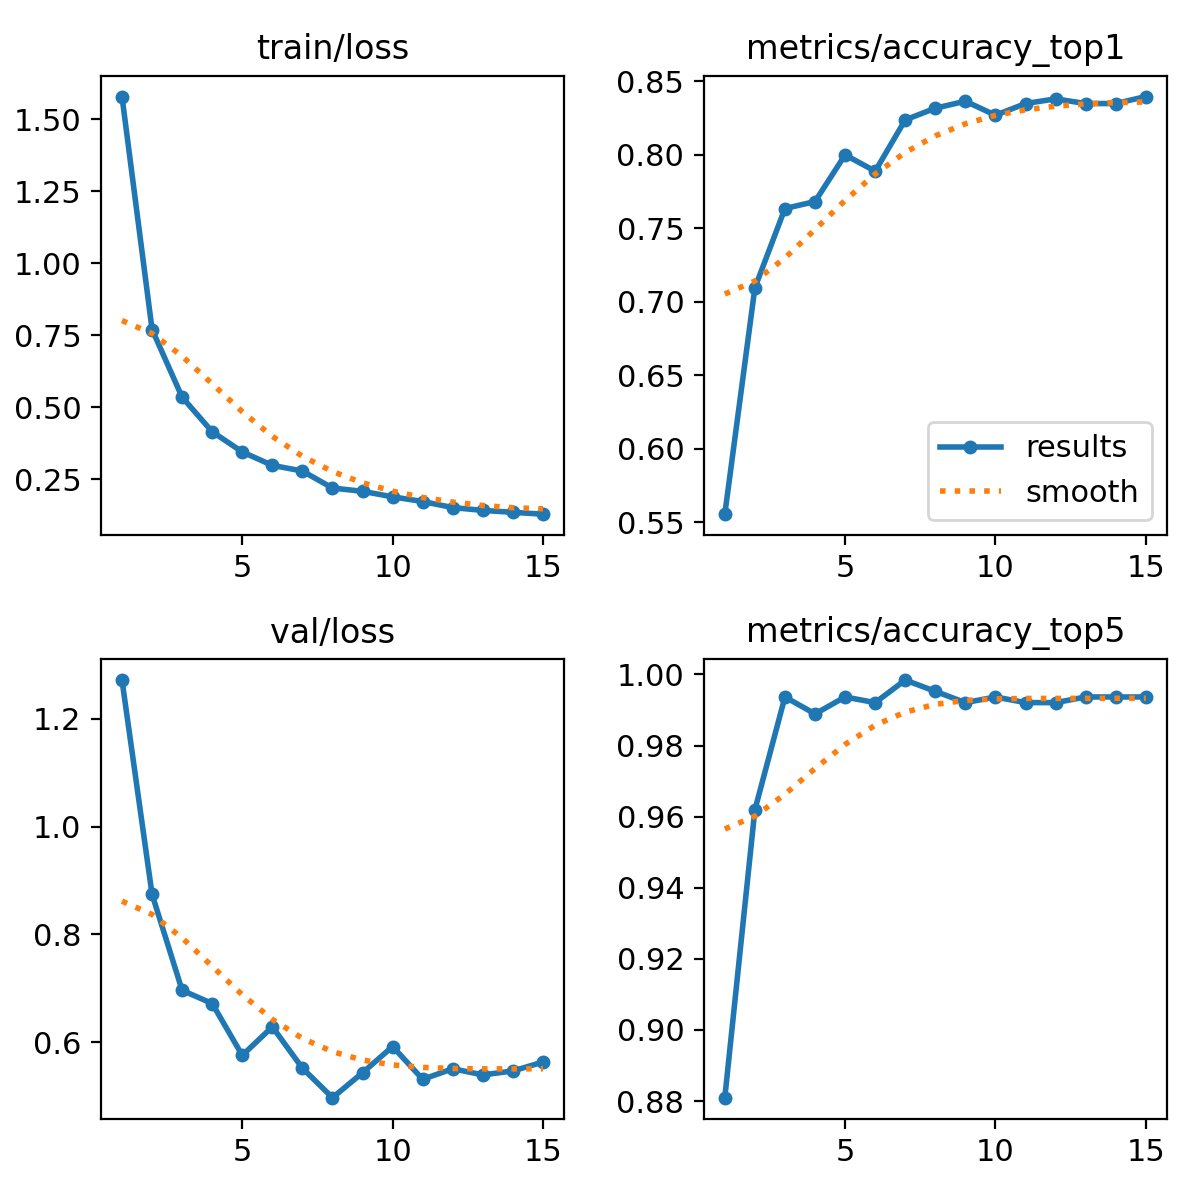

cls3_v2


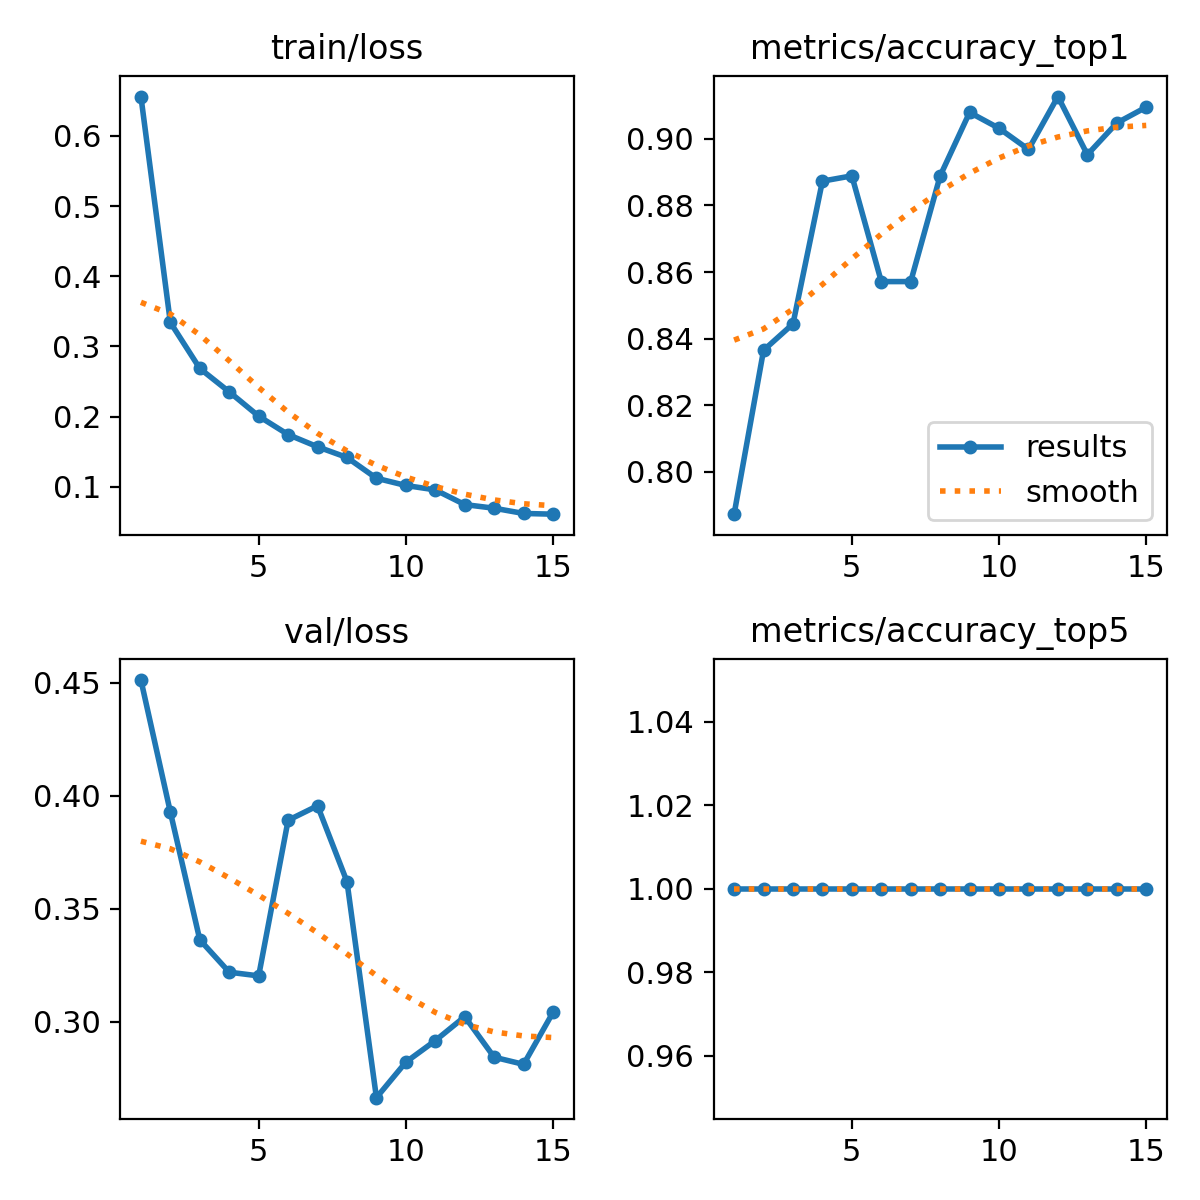

In [10]:
from IPython.display import Image, display
for name in [RUN9, RUN3]:
    p = RUNS / name / "results.png"
    if p.exists():
        print(name); display(Image(str(p), width=900))

## 10. הערכה על test

ה-test לא שימש באימון ולא בבחירת ה-epoch, ולכן זו המדידה האמיתית של המודל.

**לא להסתפק ב-accuracy** – כשהדאטה לא מאוזן, מודל שעונה "spaghetti" כמעט תמיד מקבל accuracy גבוה.
מסתכלים על precision ו-recall לכל מחלקה, ועל ה-confusion matrix.

### 10.1 חיזוי על כל תמונות ה-test

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt, pandas as pd
def predict_test(weights, data_dir):
    model = YOLO(weights)
    y_true, y_pred = [], []
    for c in sorted(os.listdir(data_dir / "test")):
        for r in model.predict(source=str(data_dir / "test" / c), imgsz=IMGSZ, stream=True, verbose=False):
            y_true.append(c); y_pred.append(r.names[r.probs.top1])
    return y_true, y_pred

def report(name, data_dir):
    y_true, y_pred = predict_test(RUNS / name / "weights" / "best.pt", data_dir)
    labels = sorted(set(y_true))
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, labels=labels, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(xticks_rotation=45, values_format=".2f", cmap="Blues")
    plt.title(f"{name} – test (rows = true class)"); plt.tight_layout(); plt.show()
    return y_true, y_pred

### 10.2 מודל 9 מחלקות

===== cls9_v2 =====
                  precision    recall  f1-score   support

      detachment      0.714     0.556     0.625         9
          normal      0.727     0.923     0.814        26
  over_extrusion      0.625     0.333     0.435        15
poor_first_layer      0.529     0.692     0.600        13
       spaghetti      0.933     0.921     0.927       365
       stringing      0.838     0.889     0.863        99
 under_extrusion      0.643     0.360     0.462        25
         warping      0.810     0.911     0.857        56
            zits      0.953     0.968     0.961        63

        accuracy                          0.876       671
       macro avg      0.753     0.728     0.727       671
    weighted avg      0.874     0.876     0.872       671



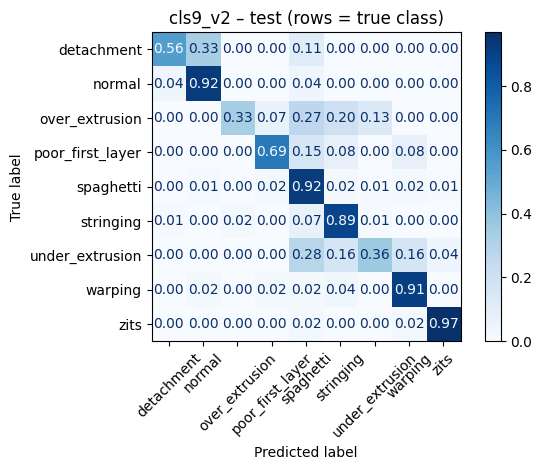

In [18]:
y9_true, y9_pred = report(RUN9, DATA9)

### 10.3 מודל 3 קבוצות
שני המדדים שהכי חשובים למערכת:
- **recall של `stop`** – כמה מהכשלים הקריטיים נתפסו
- **שיעור התראות שווא** – כמה הדפסות תקינות היו נעצרות (normal שסווג כ-stop)

===== cls3_v2 =====
              precision    recall  f1-score   support

         log      0.868     0.911     0.889       202
      normal      0.800     0.923     0.857        26
        stop      0.953     0.923     0.938       443

    accuracy                          0.920       671
   macro avg      0.874     0.919     0.895       671
weighted avg      0.922     0.920     0.920       671



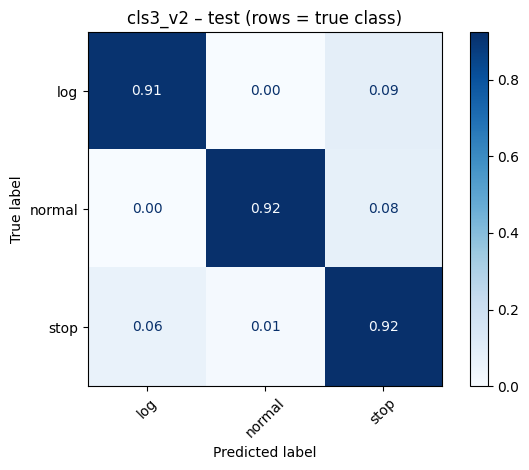

stop recall:      92.3%  (443 images)
false-stop rate:  7.7%  (26 normal images)


In [19]:
y3_true, y3_pred = report(RUN3, DATA3)

normal = [p for t, p in zip(y3_true, y3_pred) if t == "normal"]
stop   = [p for t, p in zip(y3_true, y3_pred) if t == "stop"]
print(f"stop recall:      {sum(p == 'stop' for p in stop) / len(stop):.1%}  ({len(stop)} images)")
print(f"false-stop rate:  {sum(p == 'stop' for p in normal) / len(normal):.1%}  ({len(normal)} normal images)")

### 10.4 השוואה בין המודלים
את מודל 9 המחלקות ממפים לשלוש הקבוצות, כדי להשוות את שני המודלים על אותה החלטה.

In [20]:
from sklearn.metrics import accuracy_score, f1_score
y9_true_g = [GROUPS[c] for c in y9_true]
y9_pred_g = [GROUPS[c] for c in y9_pred]

def summary(t, p):
    stop_idx = [i for i, x in enumerate(t) if x == "stop"]
    norm_idx = [i for i, x in enumerate(t) if x == "normal"]
    return {"accuracy": accuracy_score(t, p),
            "macro F1": f1_score(t, p, average="macro"),
            "stop recall": sum(p[i] == "stop" for i in stop_idx) / len(stop_idx),
            "false-stop rate": sum(p[i] == "stop" for i in norm_idx) / len(norm_idx)}

pd.DataFrame({f"{RUN9} → groups": summary(y9_true_g, y9_pred_g),
              RUN3: summary(y3_true, y3_pred)}).style.format("{:.1%}")

,cls9_v2 → groups,cls3_v2
accuracy,92.3%,92.0%
macro F1,88.4%,89.5%
stop recall,94.6%,92.3%
false-stop rate,7.7%,7.7%


### 10.5 לתעד
לרשום ב-Notion: תאריך, מספר תמונות לכל מחלקה, וטבלת ההשוואה מ-10.4.
זה ה-baseline – כל שיפור עתידי (עוד דאטה, איזון, מודל גדול יותר) נמדד מולו.

In [21]:
import json, datetime
EVAL = RUNS / "evaluation"; EVAL.mkdir(exist_ok=True)
stamp = datetime.date.today().isoformat()

# comparison table (10.4)
table = pd.DataFrame({f"{RUN9} → groups": summary(y9_true_g, y9_pred_g),
                      RUN3: summary(y3_true, y3_pred)})
table.to_csv(EVAL / f"{stamp}_comparison.csv")

# per-model report + test confusion matrix
for name, (t, p) in {RUN9: (y9_true, y9_pred), RUN3: (y3_true, y3_pred)}.items():
    rep = classification_report(t, p, digits=3, zero_division=0, output_dict=True)
    json.dump(rep, open(EVAL / f"{stamp}_{name}_report.json", "w"), indent=1)
    labels = sorted(set(t))
    cm = confusion_matrix(t, p, labels=labels, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(xticks_rotation=45, values_format=".2f", cmap="Blues")
    plt.title(f"{name} – test"); plt.tight_layout()
    plt.savefig(EVAL / f"{stamp}_{name}_test_cm.png", dpi=150); plt.close()

print(table.round(3))
print("saved to", EVAL)

                 cls9_v2 → groups  cls3_v2
accuracy                    0.923    0.920
macro F1                    0.884    0.895
stop recall                 0.946    0.923
false-stop rate             0.077    0.077
saved to /content/drive/MyDrive/Final_Project/runs/evaluation
